In [1]:
# Question 1.a.
upper_class <- c(14, 6, 7)
lower_class <-c(7, 7, 1)

# Table
table_of_study <- rbind(
  "Upper class" = upper_class,
  "Lower class" = lower_class
)

colnames(table_of_study) <- c(
  "Not stopped",
  "Bribe requested",
  "Stopped/given warning"
)

In [2]:
## Calculate the totals

# Calculate row totals
row_totals <- rowSums(table_of_study)

# Calculate column totals
column_totals <- colSums(table_of_study)

# Calculate grand total
grand_total <- sum(table_of_study)

table_of_study

,Not stopped,Bribe requested,Stopped/given warning
Upper class,14,6,7
Lower class,7,7,1


In [3]:
### Assumptions

In [4]:
#### State Hypotheses
# H₀ : The variables are statistically independent
# H₁ : The variables are statistically dependent

# Frequency observed (fo) = number of observed sample
# Frequency expected (fe) = what we would expect for independent samples
### If H₀ is true, then we would expect fo = fe

# Expected frequency for one cell
fe <- outer(row_totals, column_totals) / grand_total
fo <- table_of_study


In [5]:
### Calculate the χ2 statistic
chi_test_statistic <- sum((fo - fe)^2 / fe)
chi_test_statistic

[1] 3.791168

In [6]:
### Calculating p-values for Chi-squared tests
# Frequency >= 5 for all cells, but this is not true for our table
df <- (nrow(table_of_study) - 1) *(ncol(table_of_study) - 1)
df
# Check expected frequencies
if (any(fe < 5)) {
  warning("Some expected frequencies are below 5. Chi-squared approximation may be unreliable.")
}

[1] 2

Warning message:
"Some expected frequencies are below 5. Chi-squared approximation may be unreliable."


In [7]:
p_value <- pchisq(chi_test_statistic, df, lower.tail=FALSE)
p_value
#Since p-value ≈ 0.15 > 0.05%, we cannot reject the null hypothesis (H₀) at the common significance level (0.05 / 5%)
# Fail to reject H₀ at 0.05 significance level

[1] 0.1502306

In [8]:
# Print the chi-squared statistic, df, and p-value
test_result <- chisq.test(table_of_study, correct = FALSE)
test_result
# Warning message given as this is a small sample, but as the p-value is much larger than the significance level, we accept this outcome

## The calculated chi-squared test statistic is χ2=3.7912, with 2 degrees of freedom and a p-value of approximately 0.1502.
# There is insufficient statistical evidence to conclude that social class and the outcome category are associated.

Warning message in chisq.test(table_of_study, correct = FALSE):
"Chi-squared approximation may be incorrect"



	Pearson's Chi-squared test

data:  table_of_study
X-squared = 3.7912, df = 2, p-value = 0.1502


In [9]:
### Formal Statistical Conclusion
### Address the Small Sample Size Warning


In [10]:
# Question 1.b.
p_value <- pchisq(
  chi_test_statistic,
  df = df,
  lower.tail = FALSE
)

p_value
# p=0.1502>α=0.1


[1] 0.1502306

In [11]:
fisher.test(table_of_study)
# Therefore, we fail to reject the null hypothesis.

# There is insufficient statistical evidence at the 10% significance level to conclude that social class and the outcome category are associated.


	Fisher's Exact Test for Count Data

data:  table_of_study
p-value = 0.1553
alternative hypothesis: two.sided


In [12]:
#Question 1.c.
## Standardized residuals
# How far away is each observed value from "expectation"
SR_adjusted <- (fo - fe) /
  sqrt(fe * outer(
    1 - row_totals / grand_total,
    1 - column_totals / grand_total
  ))
SR_adjusted

,Not stopped,Bribe requested,Stopped/given warning
Upper class,0.3220306,-1.641957,1.523026
Lower class,-0.3220306,1.641957,-1.523026


In [13]:
# Standardized (Pearson) residuals
SR_pearson <- test_result$residuals
SR_pearson

,Not stopped,Bribe requested,Stopped/given warning
Upper class,0.1360828,-0.8153742,0.818923
Lower class,-0.1825742,1.0939393,-1.098701


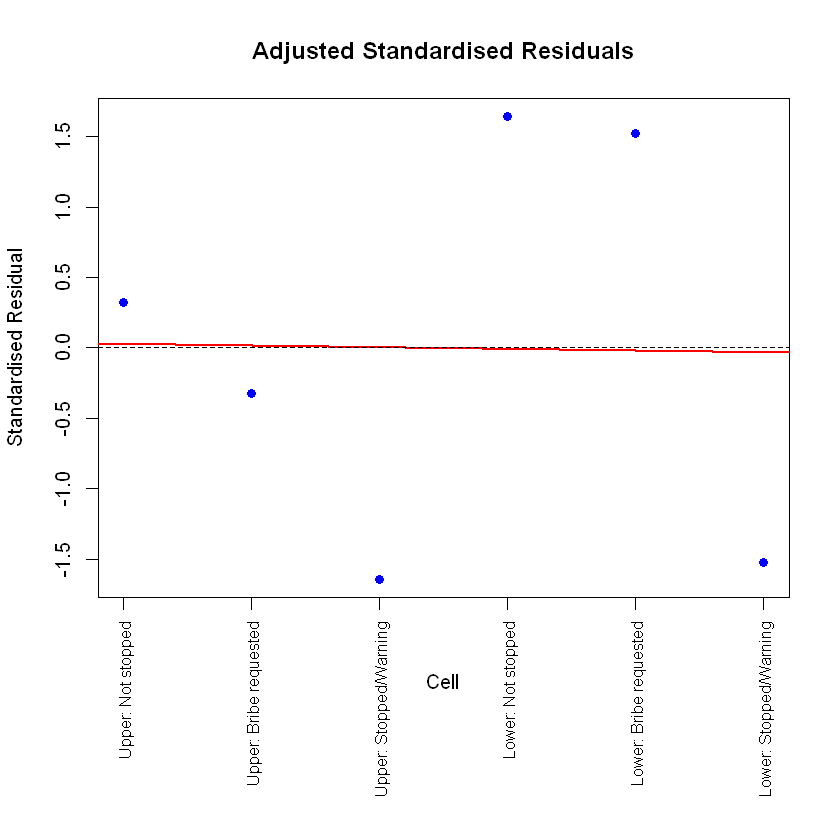

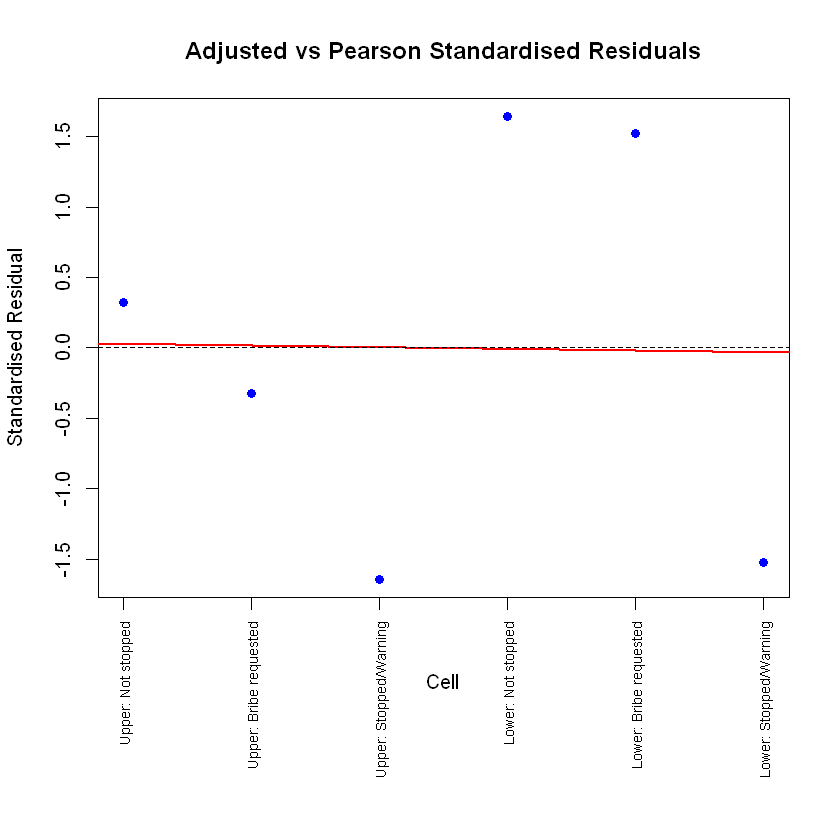

In [14]:
# How might the standardized residuals help you interpret the results?
# Increase bottom margin for long labels
par(mar = c(10, 4, 4, 2) + 0.1)

observation_names <- c(
  "Upper: Not stopped",
  "Upper: Bribe requested",
  "Upper: Stopped/Warning",
  "Lower: Not stopped",
  "Lower: Bribe requested",
  "Lower: Stopped/Warning"
)

plot(
  as.vector(SR_adjusted),
  pch = 19,
  col = "blue",
  xlab = "Cell",
  ylab = "Standardised Residual",
  main = "Adjusted Standardised Residuals",
  ylim = range(c(SR_adjusted, SR_pearson), na.rm = TRUE),
  xaxt = "n"
)

axis(1, at = 1:6, labels = observation_names,
     las = 2, cex.axis = 0.8)

abline(
  lm(as.vector(SR_adjusted) ~ seq_along(as.vector(SR_adjusted))),
  col = "red",
  lwd = 2
)

abline(h = 0, col = "black", lty = 2)
# Observation names
observation_names <- c(
  "Upper: Not stopped",
  "Upper: Bribe requested",
  "Upper: Stopped/Warning",
  "Lower: Not stopped",
  "Lower: Bribe requested",
  "Lower: Stopped/Warning"
)

# Plot adjusted standardised residuals
plot(
  as.vector(SR_adjusted),
  pch = 19,
  col = "blue",
  xlab = "Cell",
  ylab = "Standardised Residual",
  main = "Adjusted vs Pearson Standardised Residuals",
  ylim = range(c(SR_adjusted, SR_pearson), na.rm = TRUE),
  xaxt = "n"
)

# Add observation names to x-axis
axis(1, at = 1:6, labels = observation_names, las = 2, cex.axis = 0.7)

# Add best-fit line
abline(
  lm(as.vector(SR_adjusted) ~ seq_along(as.vector(SR_adjusted))),
  col = "red",
  lwd = 2
)

# Add reference line at zero
abline(h = 0, col = "black", lty = 2)

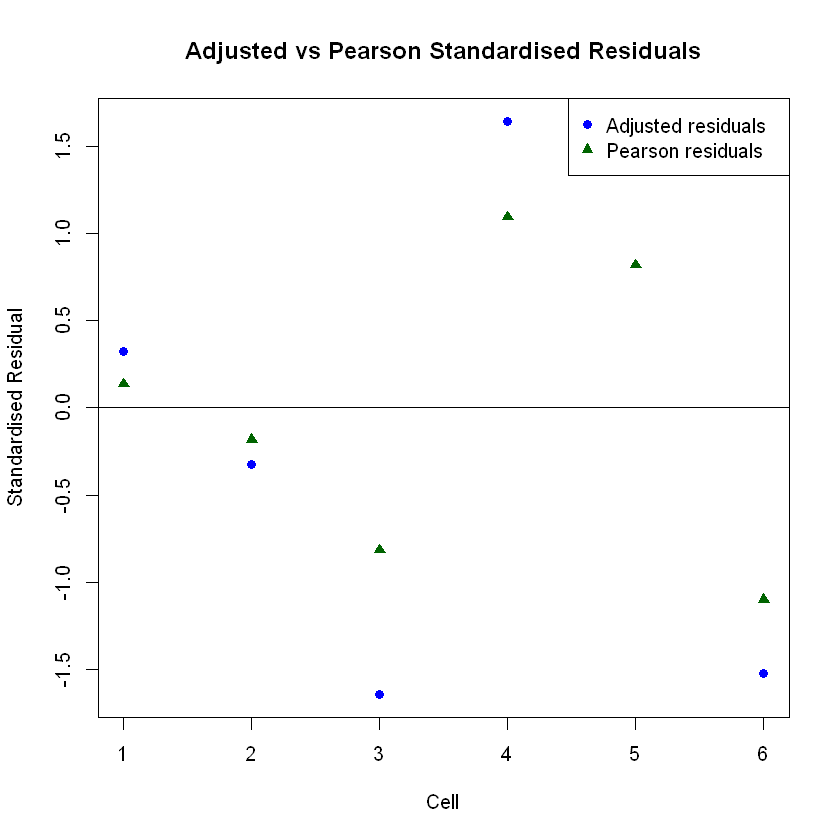

In [15]:
# Combine adjusted and Pearson standardised residuals
plot(
  as.vector(SR_adjusted),
  pch = 19,
  col = "blue",
  xlab = "Cell",
  ylab = "Standardised Residual",
  main = "Adjusted vs Pearson Standardised Residuals",
  ylim = range(c(SR_adjusted, SR_pearson), na.rm = TRUE)
)

# Add Pearson residuals
points(
  as.vector(SR_pearson),
  pch = 17,
  col = "darkgreen"
)

# Add reference lines
abline(h = 0, col = "black", lty = 1)
abline(h = c(-1.96, 1.96), col = "red", lty = 2)

# Add legend
legend(
  "topright",
  legend = c("Adjusted residuals", "Pearson residuals"),
  col = c("blue", "darkgreen"),
  pch = c(19, 17)
)

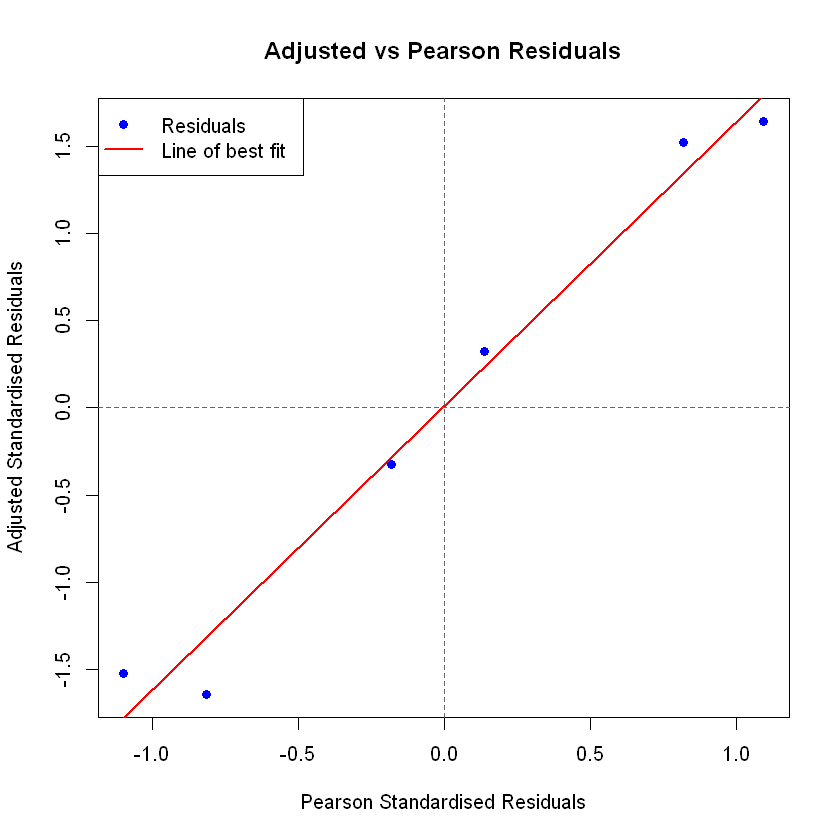

In [16]:
# Scatterplot: Adjusted vs Pearson residuals
plot(
  as.vector(SR_pearson),
  as.vector(SR_adjusted),
  pch = 19,
  col = "blue",
  xlab = "Pearson Standardised Residuals",
  ylab = "Adjusted Standardised Residuals",
  main = "Adjusted vs Pearson Residuals"
)

# Add line of best fit
abline(
  lm(as.vector(SR_adjusted) ~ as.vector(SR_pearson)),
  col = "red",
  lwd = 2
)

# Add reference lines
abline(h = 0, col = "grey40", lty = 2)
abline(v = 0, col = "grey40", lty = 2)

# Add legend
legend(
  "topleft",
  legend = c("Residuals", "Line of best fit"),
  col = c("blue", "red"),
  pch = c(19, NA),
  lty = c(NA, 1),
  lwd = c(NA, 2)
)

In [17]:
women <- read.csv(url(
  "https://raw.githubusercontent.com/kosukeimai/qss/master/PREDICTION/women.csv"
))

In [18]:
summary(women)

       GP         village       reserved          female         irrigation    
 Min.   :  1   Min.   :1.0   Min.   :0.0000   Min.   :0.0000   Min.   : 0.000  
 1st Qu.: 41   1st Qu.:1.0   1st Qu.:0.0000   1st Qu.:0.0000   1st Qu.: 0.000  
 Median : 81   Median :1.5   Median :0.0000   Median :0.0000   Median : 0.000  
 Mean   : 81   Mean   :1.5   Mean   :0.3354   Mean   :0.3851   Mean   : 3.264  
 3rd Qu.:121   3rd Qu.:2.0   3rd Qu.:1.0000   3rd Qu.:1.0000   3rd Qu.: 2.000  
 Max.   :161   Max.   :2.0   Max.   :1.0000   Max.   :1.0000   Max.   :90.000  
     water       
 Min.   :  0.00  
 1st Qu.:  3.00  
 Median :  9.00  
 Mean   : 17.84  
 3rd Qu.: 20.00  
 Max.   :340.00  

In [19]:
str(women)

'data.frame':	322 obs. of  6 variables:
 $ GP        : int  1 1 2 2 3 3 4 4 5 5 ...
 $ village   : int  2 1 2 1 2 1 2 1 2 1 ...
 $ reserved  : int  1 1 1 1 0 0 0 0 0 0 ...
 $ female    : int  1 1 1 1 0 0 0 0 0 0 ...
 $ irrigation: int  0 5 2 4 0 0 4 0 0 0 ...
 $ water     : int  10 0 2 31 0 0 7 12 28 0 ...


In [20]:
# Assumptions
# We assume the reservation policy was randomly assigned, making treatment and control groups comparable on average
# It also assumes the observations are independent and the status of one village does not influence the status of another; however, outcomes may be correlated within councils.
# Two villages are associated with each GP, which could affect the standard errors.
# Random assignment helps identify the causal effect, but it does not guarantee independent observations or eliminate every possible issue with statistical inference.
# Unit of random assignment: The GP, not the individual village.
# The sample size is 322 observations (villages), but 161 villages. Each GP has two villages, so there are approximately 161 GPs. Treatment group: Villages in GPs reserved for female leaders (reserved = 1). Control group: Villages in GPs not reserved for female leaders (reserved = 0).

# H₀ : β1=0 The reservation policy has no effect on the average number of drinking-water facilities
# H₁ : β1≠0 The reservation policy has an effect on the average number of drinking-water facilities (increase or decrease)
# β1 represents the population regression coefficient

# Create the variables table
variables_table <- data.frame(
  Variable = c("GP", "village", "reserved", "female",
               "irrigation", "water"),
  Data_Type = c(
    "Categorical identifier for the GP",
    "Categorical identifier for the village within a GP",
    "Binary (0 = not reserved, 1 = reserved)",
    "Binary (0 = male leader, 1 = female leader)",
    "Quantitative, discrete count",
    "Quantitative, discrete count (outcome variable)"
  )
)

# Display the table
knitr::kable(variables_table, caption = "Description of Variables")



Table: Description of Variables

|Variable   |Data_Type                                          |
|:----------|:--------------------------------------------------|
|GP         |Categorical identifier for the GP                  |
|village    |Categorical identifier for the village within a GP |
|reserved   |Binary (0 = not reserved, 1 = reserved)            |
|female     |Binary (0 = male leader, 1 = female leader)        |
|irrigation |Quantitative, discrete count                       |
|water      |Quantitative, discrete count (outcome variable)    |

In [21]:
# Run the bivariate regression
model <- lm(water ~ reserved, data = women)

# Display the regression results
summary(model)


Call:
lm(formula = water ~ reserved, data = women)

Residuals:
    Min      1Q  Median      3Q     Max 
-23.991 -14.738  -7.865   2.262 316.009 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)   14.738      2.286   6.446 4.22e-10 ***
reserved       9.252      3.948   2.344   0.0197 *  
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 33.45 on 320 degrees of freedom
Multiple R-squared:  0.01688,	Adjusted R-squared:  0.0138 
F-statistic: 5.493 on 1 and 320 DF,  p-value: 0.0197
